# code_053 · Scaling and numerical conditioning

**Book:** section 11.2. A self-contained preprocessing laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_11_GUIDE.md), [run evidence](../CHAPTER_11_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_053).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. Model-family comparisons and documentary contract checks retain their declared limits; there are no field-validity or universal-preprocessing claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1153;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1153


<a id="units"></a>
## The same physical dataset in two unit systems

Generate 550 independent members: load 10–100 kN, length 2–5 m, temperature 280–320 K. The target displacement in mm is .2+.02*load+.4*length+.015*(temperature-300)+Normal(0,.1). Fix train/development/final counts 300/100/150; compare load in kN and N without changing any physics. No hyperparameter or procedure selection occurs. Fixed candidates: 5-neighbor Euclidean regression, Ridge alpha=10 (intercept unpenalized), histogram boosting 80 iterations, 7 leaves, learning rate .1, minimum leaf 15, no early stopping, fixed seed. These are comparisons of whole procedures, not equal-capacity estimators.

For each model use no transform, training StandardScaler, training median/IQR RobustScaler, or per-row L2 Normalizer. The last changes each member's magnitude and is included to expose its different meaning, not as a recommendation for mixed physical units. All fitted transformations use only training rows.


In [2]:
from sklearn.preprocessing import StandardScaler,RobustScaler,Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
load=rng.uniform(10,100,550);length=rng.uniform(2,5,550);temperature=rng.uniform(280,320,550)
X=np.column_stack([load,length,temperature]);y=.2+.02*load+.4*length+.015*(temperature-300)+rng.normal(0,.1,550)
tr=np.arange(300);dv=np.arange(300,400);te=np.arange(400,550)
assert not set(tr)&set(te)
def model(name):
 if name=='neighbors':return KNeighborsRegressor(n_neighbors=5)
 if name=='ridge':return Ridge(alpha=10)
 return HistGradientBoostingRegressor(max_iter=80,max_leaf_nodes=7,min_samples_leaf=15,learning_rate=.1,early_stopping=False,random_state=SEED)
def scaling(name):return {'none':'passthrough','standard':StandardScaler(),'robust':RobustScaler(),'row_L2':Normalizer()}[name]
metrics={};predictions={}
for units in ['kN','N']:
 A=X.copy();A[:,0]*=1 if units=='kN' else 1000
 metrics[units]={};predictions[units]={}
 for family in ['neighbors','ridge','boosted_tree']:
  metrics[units][family]={};predictions[units][family]={}
  for transform in ['none','standard','robust','row_L2']:
   fitted=make_pipeline(scaling(transform),model(family)).fit(A[tr],y[tr]);p=fitted.predict(A[te]);predictions[units][family][transform]=p
   metrics[units][family][transform]={'development_MSE_mm2':float(mean_squared_error(y[dv],fitted.predict(A[dv]))),'final_MSE_mm2':float(mean_squared_error(y[te],p))}
for family in predictions['N']:
 for transform in ['standard','robust']:np.testing.assert_allclose(predictions['N'][family][transform],predictions['kN'][family][transform],rtol=1e-9,atol=1e-9)
RESULTS['metrics']=metrics;RESULTS['scaled_unit_conversion_prediction_invariance']=True


<a id="geometry"></a>
## Inspect geometry, not only a model score

Standardization changes the distance metric and the ridge penalty expressed in original coordinates. Unit conversion followed by training standardization yields the same standardized columns here. Row normalization is not column scaling and generally erases useful radial magnitude. The centered design Gram matrix condition number diagnoses numerical geometry; it does not prove a particular solver failed or that any transform improves prediction.


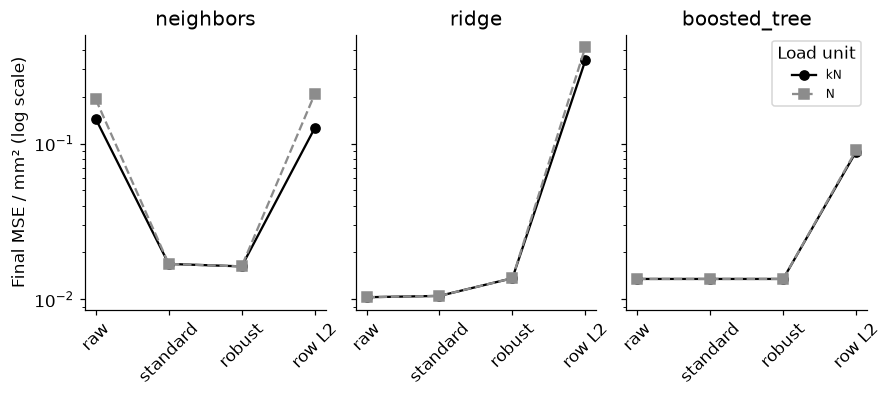

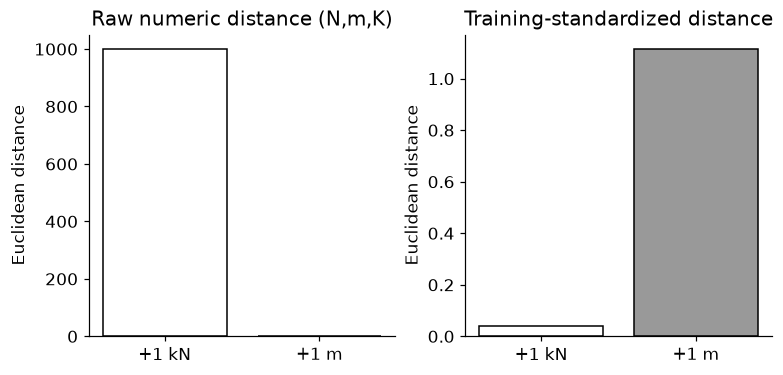

In [3]:
XN=X.copy();XN[:,0]*=1000
raw_centered=XN[tr]-XN[tr].mean(axis=0);standard=StandardScaler().fit_transform(XN[tr])
RESULTS['centered_Gram_condition_number']={'raw_N':float(np.linalg.cond(raw_centered.T@raw_centered)),'standard':float(np.linalg.cond(standard.T@standard))}
assert RESULTS['centered_Gram_condition_number']['standard']<RESULTS['centered_Gram_condition_number']['raw_N']
fig,axes=plt.subplots(1,3,figsize=(8,3.5),sharey=True)
transforms=['none','standard','robust','row_L2']
for ax,family in zip(axes,['neighbors','ridge','boosted_tree']):
 for j,units in enumerate(['kN','N']):ax.plot(np.arange(4),[metrics[units][family][t]['final_MSE_mm2'] for t in transforms],marker=['o','s'][j],ls=['-','--'][j],color=['black','.55'][j],label=units)
 ax.set(title=family,xticks=np.arange(4),xticklabels=['raw','standard','robust','row L2'],yscale='log');ax.tick_params(axis='x',labelrotation=45)
axes[0].set_ylabel('Final MSE / mm² (log scale)');axes[-1].legend(title='Load unit',fontsize=8);plt.show()
# Two physical differences have radically different raw distances in N.
a=np.array([50,3,300]);b=np.array([51,3,300]);c=np.array([50,4,300]);s=StandardScaler().fit(X[tr])
raw_dist=[float(np.linalg.norm((z-a)*np.array([1000,1,1]))) for z in (b,c)];scaled_dist=[float(np.linalg.norm(s.transform(z[None,:])-s.transform(a[None,:]))) for z in (b,c)]
fig,axes=plt.subplots(1,2,figsize=(7,3.3));labels=['+1 kN','+1 m']
for ax,values,title in zip(axes,[raw_dist,scaled_dist],['Raw numeric distance (N,m,K)','Training-standardized distance']):ax.bar(labels,values,color=['white','.6'],edgecolor='black');ax.set(title=title,ylabel='Euclidean distance')
plt.show();RESULTS['distance_fixture']={'raw_mixed_unit':raw_dist,'standardized':scaled_dist}


In [4]:
summary={'example_id':'code_053','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['unit conversion versus learned scaling', 'distance and ridge penalty geometry', 'standard robust and row normalization', 'model-dependent sensitivity and conditioning'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["unit conversion versus learned scaling", "distance and ridge penalty geometry", "standard robust and row normalization", "model-dependent sensitivity and conditioning"], "elapsed_seconds": 0.532, "example_id": "code_053", "hardware": "Darwin arm64 CPU", "results": {"centered_Gram_condition_number": {"raw_N": 813017630.8611307, "standard": 1.2398900663379773}, "distance_fixture": {"raw_mixed_unit": [1000.0, 1.0], "standardized": [0.03919105246510313, 1.1148522790638]}, "metrics": {"N": {"boosted_tree": {"none": {"development_MSE_mm2": 0.015497612234927224, "final_MSE_mm2": 0.013526792209823259}, "robust": {"development_MSE_mm2": 0.015497612234927224, "final_MSE_mm2": 0.013526792209823259}, "row_L2": {"development_MSE_mm2": 0.08671490706683346, "final_MSE_mm2": 0.0904525138964082}, "standard": {"development_MSE_mm2": 0.015497612234927224, "final_MSE_mm2": 0.013526792209823259}}, "neighbors": {"none": {"development_MSE_mm2": 0.18987284976